In [1]:
import pandas as pd

traffic = pd.read_csv(
    "../data/traffic_5grids.csv",
    parse_dates=["datetime"]
)

display(traffic.head())

FileNotFoundError: [Errno 2] No such file or directory: '../data/traffic_5grids.csv'

In [2]:
import os

print("Current notebook directory:", os.getcwd())

print("\nFiles in data folder:")
print(os.listdir("../data"))

Current notebook directory: C:\Users\jayasree singarapu\OneDrive\Desktop\5G_TRAFFIC_PREDICTION\notebooks

Files in data folder:
[]


In [3]:
import pandas as pd

traffic = pd.read_csv(
    "../data/traffic_5grids.csv",
    parse_dates=["datetime"]
)

print("Dataset shape:", traffic.shape)
display(traffic.head())

Dataset shape: (21600, 4)


,GridID,TimeInterval,internet,datetime
0,1,1383260400000,11.028366,2013-10-31 23:00:00+00:00
1,1,1383261000000,11.127101,2013-10-31 23:10:00+00:00
2,1,1383261600000,10.892771,2013-10-31 23:20:00+00:00
3,1,1383262200000,8.622424,2013-10-31 23:30:00+00:00
4,1,1383262800000,8.009928,2013-10-31 23:40:00+00:00


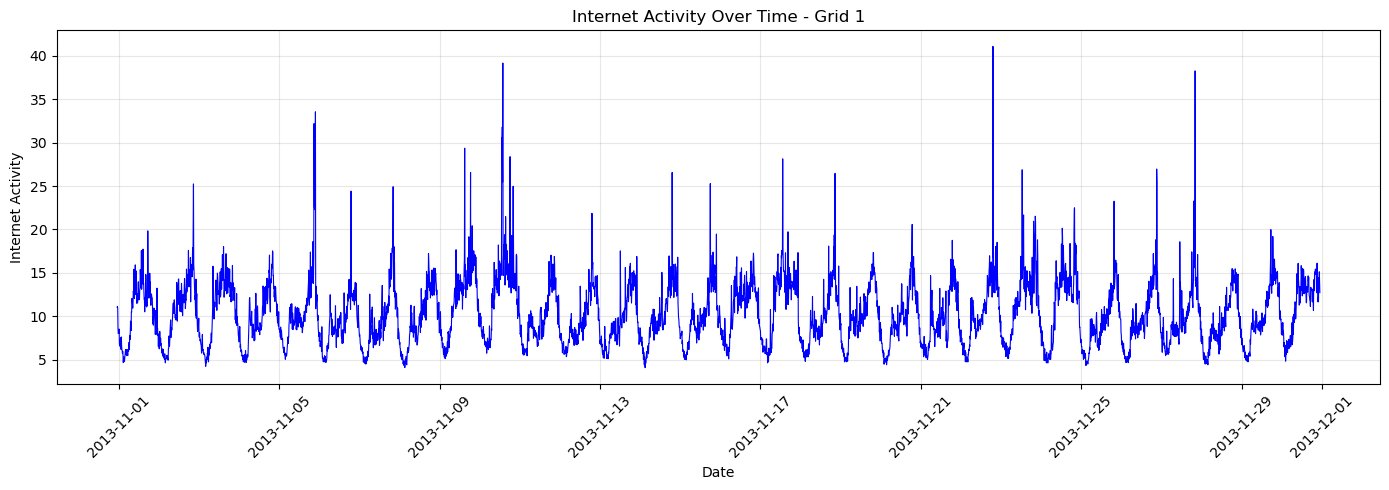

In [4]:
import matplotlib.pyplot as plt

grid1 = traffic[traffic["GridID"] == 1]

plt.figure(figsize=(14, 5))

plt.plot(
    grid1["datetime"],
    grid1["internet"],
    color="blue",
    linewidth=0.8
)

plt.title("Internet Activity Over Time - Grid 1")
plt.xlabel("Date")
plt.ylabel("Internet Activity")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

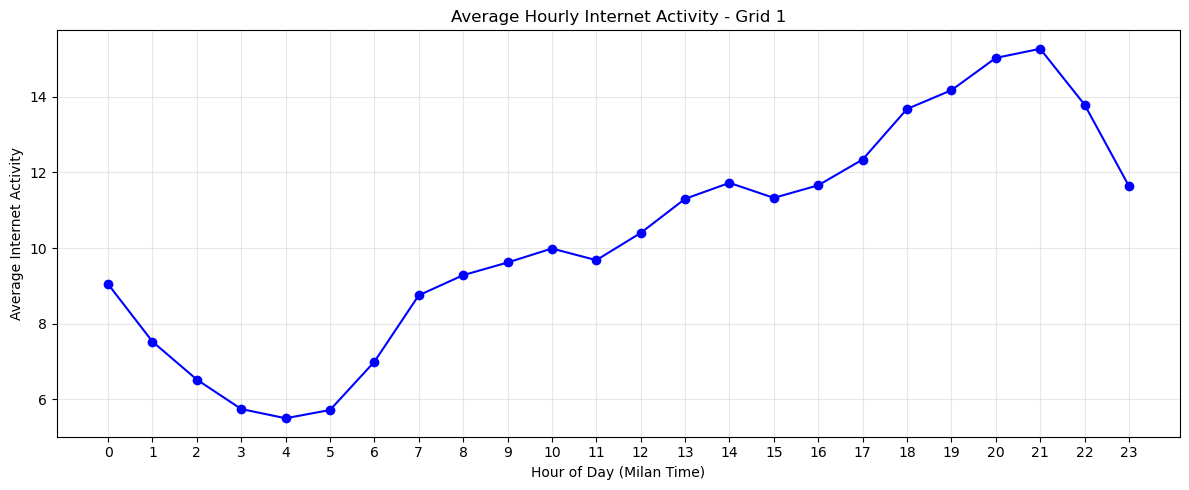

In [5]:
# Convert UTC time to Milan local time
traffic["local_datetime"] = (
    traffic["datetime"].dt.tz_convert("Europe/Rome")
)

# Extract hour
traffic["hour"] = traffic["local_datetime"].dt.hour

# Calculate average hourly activity for Grid 1
hourly_avg = (
    traffic[traffic["GridID"] == 1]
    .groupby("hour")["internet"]
    .mean()
)

# Plot
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_avg.index,
    hourly_avg.values,
    marker="o",
    color="blue"
)

plt.title("Average Hourly Internet Activity - Grid 1")
plt.xlabel("Hour of Day (Milan Time)")
plt.ylabel("Average Internet Activity")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

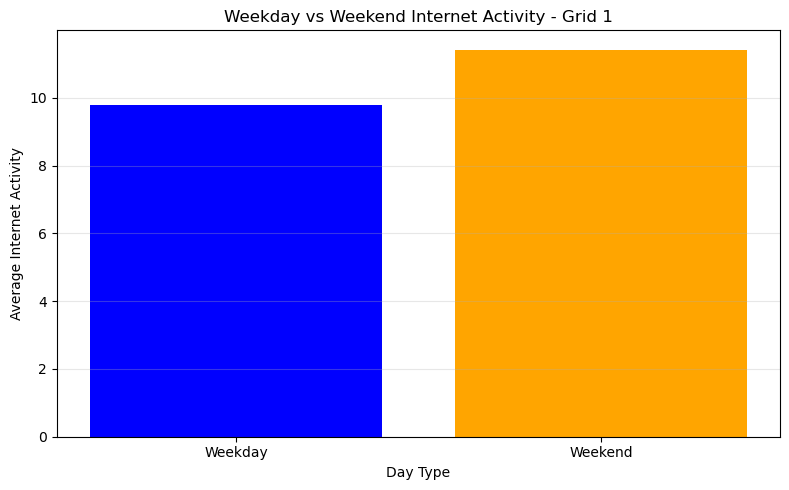

day_type
Weekday     9.793150
Weekend    11.419698
Name: internet, dtype: float64


In [6]:
# Select Grid 1
grid1 = traffic[traffic["GridID"] == 1].copy()

# Identify weekdays and weekends
grid1["day_of_week"] = grid1["local_datetime"].dt.dayofweek

grid1["day_type"] = grid1["day_of_week"].apply(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Calculate average activity
day_avg = grid1.groupby("day_type")["internet"].mean()

# Plot
plt.figure(figsize=(8, 5))

plt.bar(day_avg.index, day_avg.values, color=["blue", "orange"])

plt.title("Weekday vs Weekend Internet Activity - Grid 1")
plt.xlabel("Day Type")
plt.ylabel("Average Internet Activity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

print(day_avg)

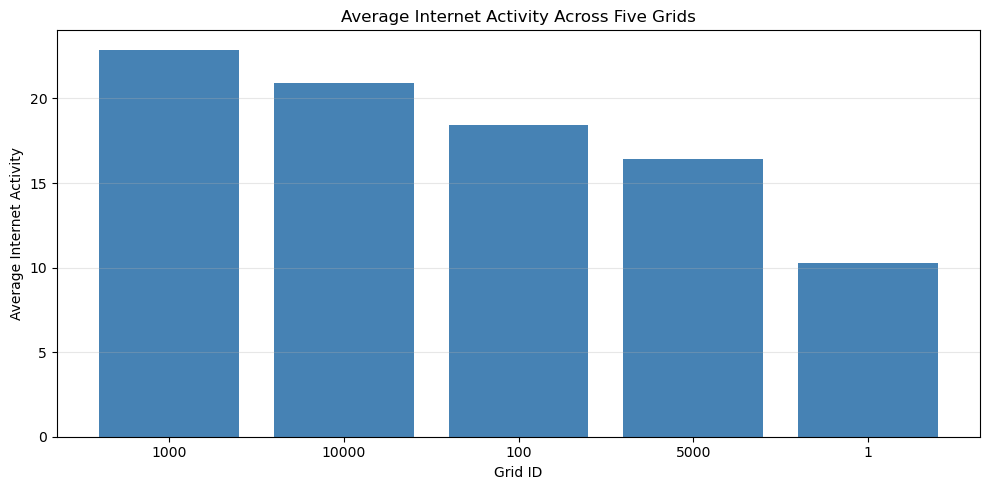

GridID
1000     22.881945
10000    20.929485
100      18.424004
5000     16.400717
1        10.281115
Name: internet, dtype: float64


In [7]:
# Calculate average internet activity for each grid
grid_avg = (
    traffic.groupby("GridID")["internet"]
    .mean()
    .sort_values(ascending=False)
)

# Plot comparison
plt.figure(figsize=(10, 5))

plt.bar(
    grid_avg.index.astype(str),
    grid_avg.values,
    color="steelblue"
)

plt.title("Average Internet Activity Across Five Grids")
plt.xlabel("Grid ID")
plt.ylabel("Average Internet Activity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

print(grid_avg)

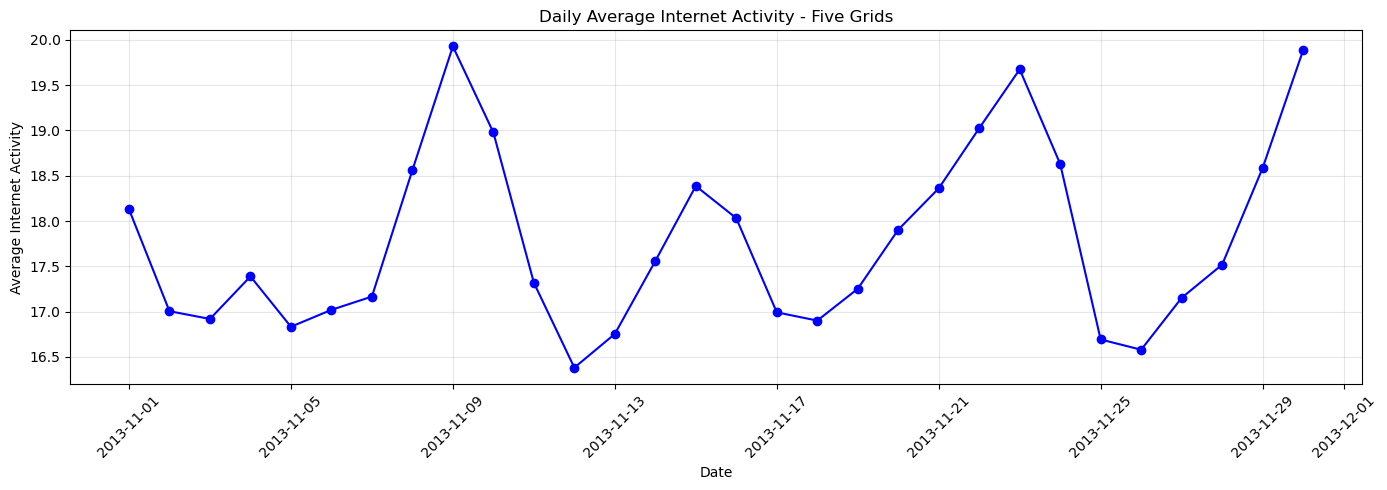

In [8]:
# Extract the date in Milan local time
traffic["date"] = (
    traffic["datetime"]
    .dt.tz_convert("Europe/Rome")
    .dt.date
)

# Calculate daily average internet activity
daily_avg = (
    traffic.groupby("date")["internet"]
    .mean()
)

# Plot daily activity
plt.figure(figsize=(14, 5))

plt.plot(
    daily_avg.index,
    daily_avg.values,
    marker="o",
    color="blue"
)

plt.title("Daily Average Internet Activity - Five Grids")
plt.xlabel("Date")
plt.ylabel("Average Internet Activity")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [9]:
# Save the EDA dataset
traffic.to_csv(
    "../data/traffic_5grids_eda.csv",
    index=False
)

print("EDA dataset saved successfully!")
print("Dataset shape:", traffic.shape)
print("Columns:", traffic.columns.tolist())

EDA dataset saved successfully!
Dataset shape: (21600, 7)
Columns: ['GridID', 'TimeInterval', 'internet', 'datetime', 'local_datetime', 'hour', 'date']


In [10]:
# Check the grid IDs available in our processed dataset

print("Selected Grid IDs:")
print(sorted(traffic["GridID"].unique()))

print("\nNumber of grids:", traffic["GridID"].nunique())

print("\nAverage internet activity per grid:")
print(
    traffic.groupby("GridID")["internet"]
    .mean()
    .round(2)
)

Selected Grid IDs:
[np.int64(1), np.int64(100), np.int64(1000), np.int64(5000), np.int64(10000)]

Number of grids: 5

Average internet activity per grid:
GridID
1        10.28
100      18.42
1000     22.88
5000     16.40
10000    20.93
Name: internet, dtype: float64
